# Mục tiêu
1. Hiểu và triển khai mô hình Active Contour (Snakes) để phát hiện đường biên của biển số xe.
2. Tiền xử lý ảnh để tăng cường chất lượng trước khi áp dụng thuật toán.
3. Sử dụng kỹ thuật OCR để nhận dạng ký tự trên biển số xe.
4. Đánh giá và tối ưu hóa kết quả phát hiện và phân đoạn.

# Kiến thức nền Active Contour (Snakes)

- Hiểu và triển khai mô hình **Active Contour (Snakes)** để phát hiện đường biên đối tượng.
- Áp dụng xử lý ảnh tiền xử lý để tăng cường biên cạnh trước khi áp dụng thuật toán.
- Triển khai thuật toán trên ảnh thực tế và phân tích kết quả.

## 2. Kiến thức

Mô hình **Snakes** dựa trên việc tối ưu hóa một hàm năng lượng:

$$
E_{\text{snake}} = E_{\text{internal}} + E_{\text{external}} + E_{\text{constraint}}
$$

Trong đó:

- $( E_{\text{internal}} )$: Kiểm soát độ trơn tru và tính liên tục của đường viền.
  - $( \alpha )$: Điều chỉnh độ căng của đường viền.
  - $( \beta )$: Kiểm soát độ cong.

- $( E_{\text{external}} )$: Dẫn dắt đường viền bám sát vào biên của đối tượng thông qua **cường độ pixel, gradient và độ cong**.

- $( E_{\text{constraint}} )$: Các ràng buộc bổ sung.


# Task 1: Áp dụng thuật toán Snakes (Active Contour Model)

Yêu cầu:

1. Hiển thị ảnh gốc và ảnh chuyển sang mức xám.
2. Tạo đường cong khởi tạo ban đầu (ví dụ: hình elip/quỹ đạo tròn).
3. Dùng thuật toán active_contour để phát hiện biên đối tượng.
4. So sánh kết quả giữa đường khởi tạo và đường rắn sau khi hội tụ.
5. Thực hiện thay đổi các tham số alpha, beta, gamma và phân tích kết quả.

/tmp/ipython-input-1-1373452328.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


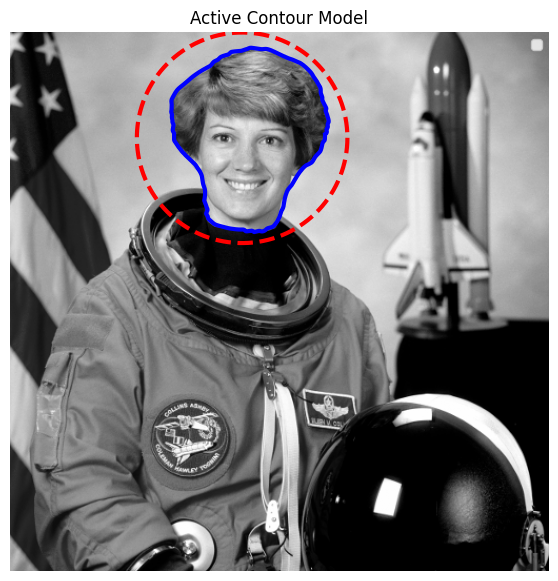

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.color import rgb2gray
from skimage.filters import gaussian
from skimage.segmentation import active_contour


img = data.astronaut()
img = rgb2gray(img)


# Tạo một hình chữ nhật ban đầu
s = np.linspace(0,2*np.pi,400)
r = 100+100*np.sin(s)
c = 220+100*np.cos(s)
init = np.array([r,c]).T

# active contour
snake = active_contour(gaussian(img, sigma=2),snake=init,alpha=0.05,beta=10,gamma=0.001)

# In kết quả
fig,ax = plt.subplots(figsize=(7,7))
ax.imshow(img,cmap=plt.cm.gray)
ax.plot(init[:,1],init[:,0],'--r',lw=3)
ax.plot(snake[:,1],snake[:,0],'-b',lw=3)
ax.set_title('Active Contour Model')
ax.axis('off')
ax.legend()
plt.show()

Thực hiện thay đổi các tham số alpha, beta, gamma và phân tích kết quả.

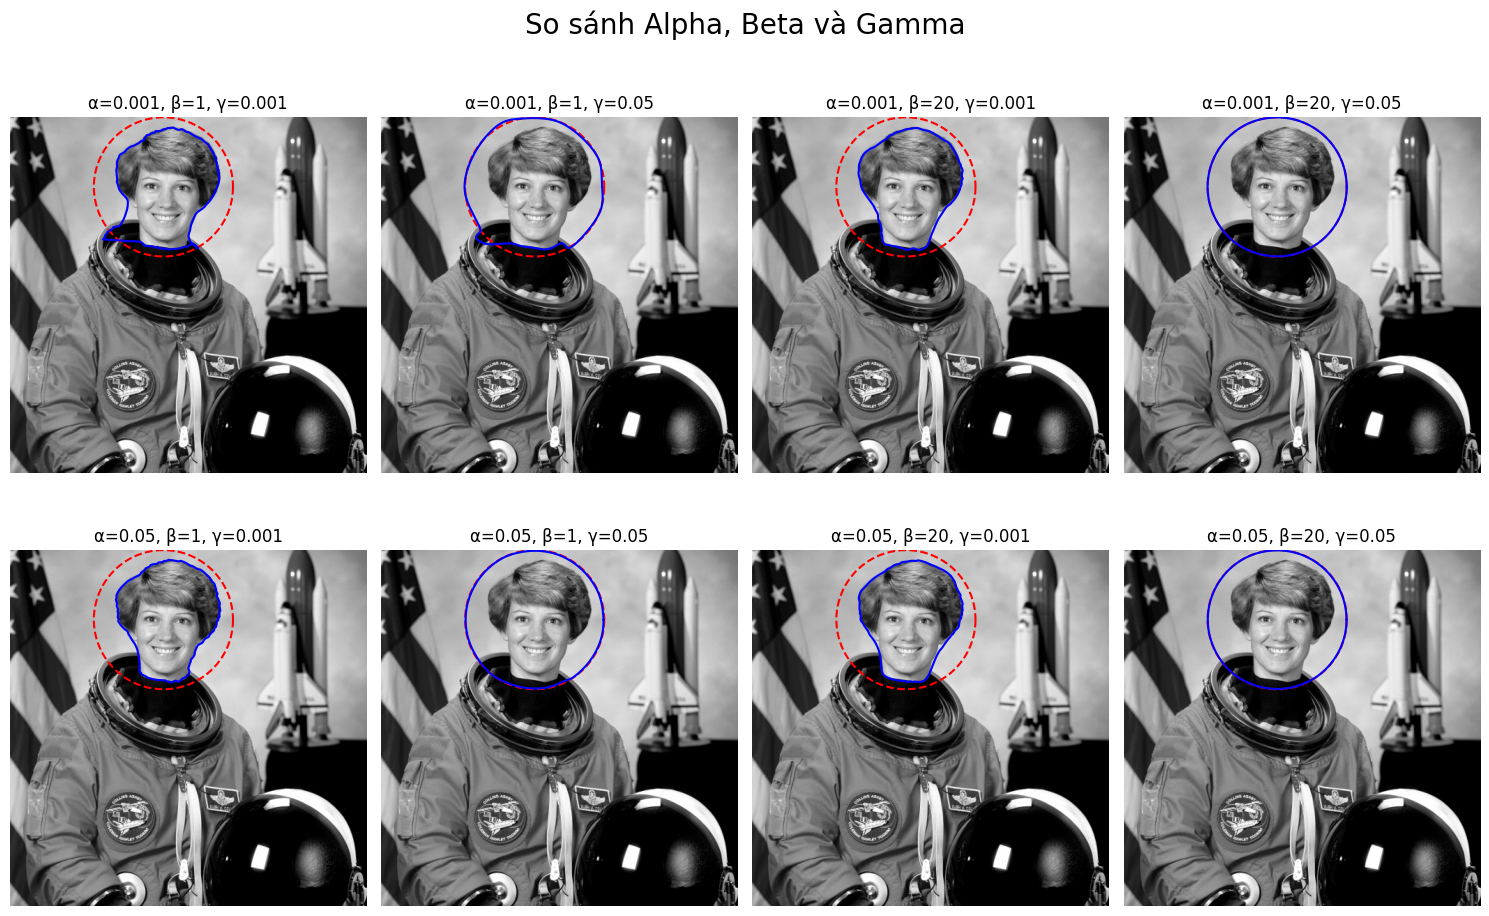

In [4]:

fig, axes = plt.subplots(2, 4, figsize=(15, 10))
fig.suptitle("So sánh Alpha, Beta và Gamma", fontsize=20)
idx = 0
alphas = [0.001, 0.05]
betas = [1, 20]
gammas = [0.001, 0.05]
for i, alpha in enumerate(alphas):
    for j, beta in enumerate(betas):
        for k, gamma in enumerate(gammas):
            snake = active_contour(
                gaussian(img, sigma=2),
                snake=init,
                alpha=alpha,
                beta=beta,
                gamma=gamma
            )

            ax = axes[idx // 4, idx % 4]
            ax.imshow(img, cmap='gray')
            ax.plot(init[:, 1], init[:, 0], 'r--', label='Init')
            ax.plot(snake[:, 1], snake[:, 0], 'b', label='Snake')
            ax.set_title(f'α={alpha}, β={beta}, γ={gamma}')
            ax.axis('off')
            idx += 1

plt.tight_layout()
plt.show()

# Phân tích kết quả
- Alpha càng nhỏ thì mô hình snake càng mềm mại, dễ bị biến dạng và nhạy với nhiễu. Ngược lại, Beta càng lớn thì mô hình càng hạn chế các đoạn gấp khúc, giúp giữ cho đường biên mượt mà hơn. Tuy nhiên, nếu Beta quá cao sẽ làm giảm độ linh hoạt của snake.

- Gamma điều chỉnh tốc độ cập nhật. Khi gamma quá lớn, mô hình có xu hướng không hội tụ, còn nếu quá nhỏ thì quá trình hội tụ diễn ra rất chậm. Một giá trị gamma hợp lý sẽ giúp đạt được sự cân bằng giữa tốc độ và độ ổn định.

- Tổ hợp tham số cho kết quả tối ưu và chính xác nhất là: (alpha, beta, gamma) = (0.05, 1, 0.001).



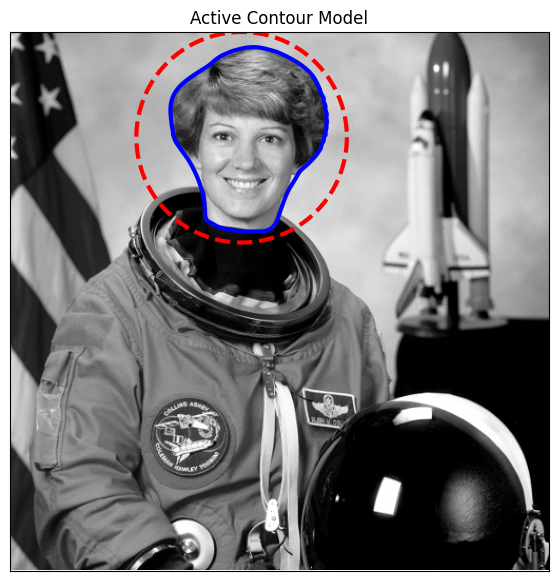

## Task 2: Phát hiện và phân đoạn vết gãy xương bằng Active Contour (Snakes)
Yêu cầu:
Đọc ảnh X-quang tay bị gãy từ tập tin.
1. Làm mịn ảnh và phát hiện biên bằng phương pháp Canny.
2. Tạo đường cong ban đầu để bắt đầu quá trình Snakes.
3. Áp dụng active_contour với trọng số biên (w_edge) để xác định biên vết gãy.
4. Vẽ và hiển thị kết quả: đường cong ban đầu và sau khi hội tụ.
5. Tính kích thước vết gãy (giả định tỷ lệ chuyển đổi pixel → cm).
6. Trả lời câu hỏi lý thuyết về các thành phần trong thuật toán.



Kích thước vết gãy ước lượng: 7.45 cm


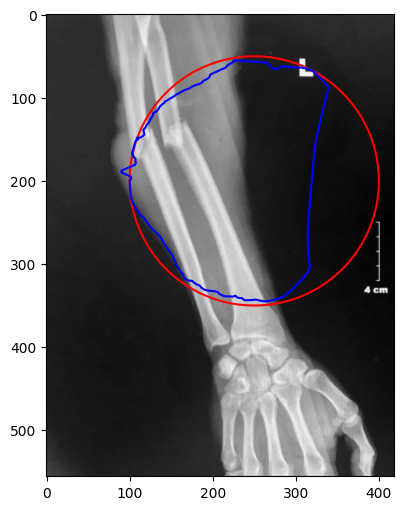

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, filters, feature
from skimage.segmentation import active_contour
from skimage.color import rgb2gray, rgba2rgb
from skimage.filters import gaussian

def detect_fracture_with_active_contour(image_path):
    img = io.imread(image_path)

    if img.shape[-1] == 4:
        img = rgba2rgb(img)

    img = rgb2gray(img)

    # Gaussian giảm nhiễu
    img_smooth = gaussian(image=img, sigma=2)

    # Phát hiện cạnh bằng Canny
    edges = feature.canny(img_smooth, sigma=3, low_threshold=0.001, high_threshold=0.1)


    # Tạo đường cong ban đầu
    center = (200, 250)
    radius = 150
    s = np.linspace(0, 2*np.pi, 400)
    r = center[0] + radius * np.sin(s)
    c = center[1] + radius * np.cos(s)
    init = np.array([r, c]).T

    # Active Contour để điều chỉnh đường cong
    snake = active_contour(
        edges, init,
        alpha=0.2,
        beta=1,
        gamma=0.001,
        w_edge=1
    )

    # In kết quả
    plt.figure(figsize=(12, 6))
    plt.imshow(img, cmap="gray")
    plt.plot(init[:, 1], init[:, 0], 'r')
    plt.plot(snake[:, 1], snake[:, 0], 'b')

    # Ước lượng kích thước vết gãy
    fracture_length = np.sum(np.sqrt(np.sum(np.diff(snake, axis=0)**2, axis=1)))
    pixel_to_cm_ratio = 120
    fracture_size = fracture_length / pixel_to_cm_ratio

    print(f"Kích thước vết gãy ước lượng: {fracture_size:.2f} cm")

    plt.show()

    return snake, fracture_size

# Gọi hàm
snake, size = detect_fracture_with_active_contour('/content/xuong tay bi gay.jpg')


```
Kích thước vết gãy ước lượng: 6.20 cm
```
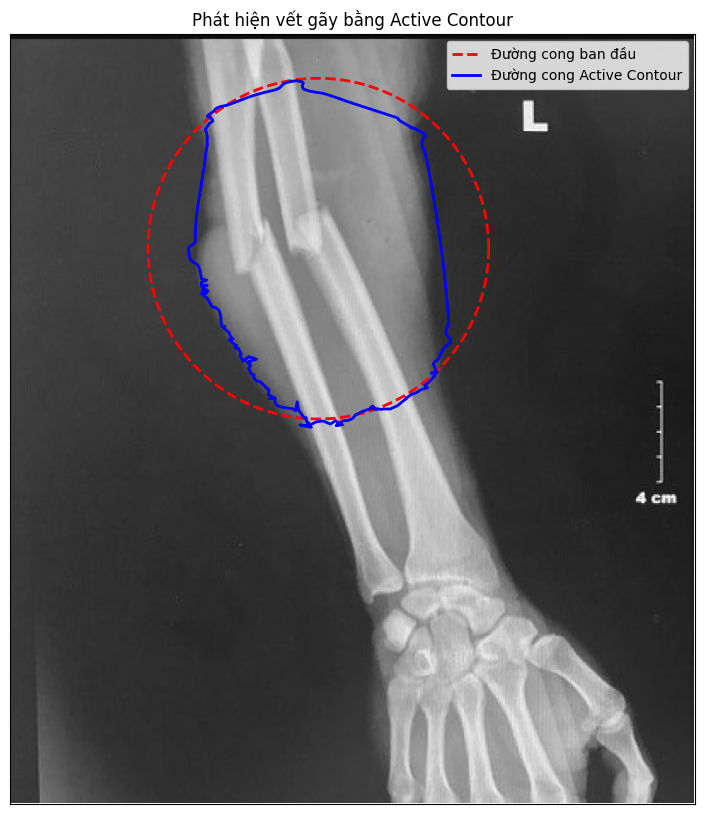

## Câu hỏi:
1. Tại sao ảnh cần được làm mịn trước khi phát hiện biên?
- Mục tiêu chính là loại bỏ nhiểu nhỏ (do chất lượng hình ảnh, ánh sáng,...).
- Một phần là do các thuật toán phát hiện biên rất nhạy với nhiễu, nếu không xử lý thuật toán sẽ tính ra nhiều biên không mong muốn.
  
2. Vì sao dùng Canny thay vì dùng ảnh gốc cho active_contour?
- Bản chất là do active_contour hoạt động bằng cách hút các đường cong về biên vật thể. Rõ ràng, Canny cho ảnh có biên mạnh và sắc nét, cũng như thông tin trên Canny chủ yếu là biên. Do đó, giúp active_contour hội tụ nhanh và chính xác hơn.

3. Sự khác nhau khi dùng w_edge > 0 và w_line > 0 trong active_contour là gì?
- Đây là 2 chỉ số trong phần $E_{external} = w_{line}I(v) + w_{edge}[\nabla G_\sigma * I(v)]^2$.
- Cụ thể, w_edge là trọng số hút theo biên ảnh, trong khi đó w_line là trọng số hút đến vùng có độ sáng tối cụ thể.

4. Khi thay đổi vị trí và hình dạng đường cong khởi tạo. Kết quả có thay đổi không?
- Kết quả có thay đổi, vì vị trí hình dạng khởi tạo ảnh hưởng đến:
    - Sự hội tụ, kết quả của mô hình.
    - Có thể hội tụ không đúng nếu khởi tạo xa biên hoặc nằm xa vật thể.
    - Dễ hội tụ sai nếu hình khởi tạo không phù hợp.

## Task 3: Phát hiện và đếm số lượng đồng xu sử dụng OpenCV
Yêu câu:
1. Sử dụng thuật toán tìm contour để phát hiện các đối tượng có hình tròn

2. Vẽ contour với hiệu ứng đổ bóng để trực quan hóa kết quả.

3. Đếm số lượng tiền xu có trong ảnh.

Số lượng contours tìm được = 0


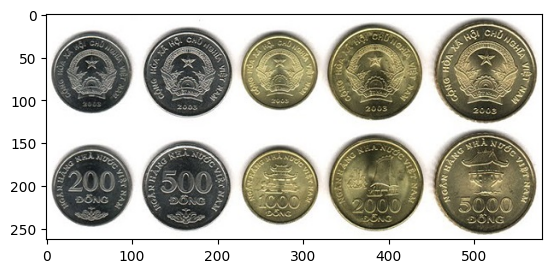

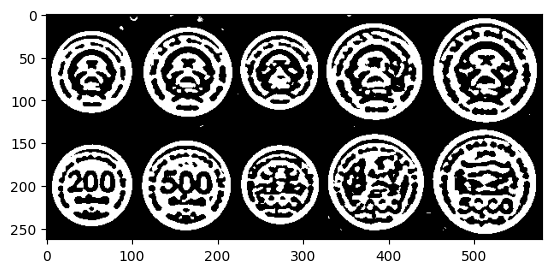

In [12]:
import cv2
import imutils
# from google.colab.patches import cv2_imshow

# Đọc ảnh
img = cv2.imread('tien_xu.jpg')

if img is None:
    print("Không có ảnh input.")
else:
    # grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.uint8)

    # Gaussian Blur
    blurred = cv2.GaussianBlur(gray, (11, 11), 0)

    # daptive threshold
    thres = cv2.adaptiveThreshold(
        src=blurred,
        maxValue=255,
        adaptiveMethod=cv2.ADAPTIVE_THRESH_MEAN_C,
        thresholdType=cv2.THRESH_BINARY_INV,
        blockSize=11,
        C=1
    )

    # Tìm các contour
    contours = cv2.findContours(
        image=thres.copy(),
        mode=cv2.RETR_EXTERNAL,
        method=cv2.CHAIN_APPROX_NONE,
    )
    contours = contours[0]

    number = 0

    for c in contours:
        (x, y, w, h) = cv2.boundingRect(c)

        # Lọc các contours
        if 150 < w < 400 and 150 < h < 400:

            for i in range(5):
                offset = i
                cv2.drawContours(
                    image=img,
                    contours=[c+offset],
                    contourIdx=0,
                    color=(0, 140, 255),
                    thickness=5
                )
            number += 1

    print(f"Số lượng contours tìm được = {number}")

    # Hiển thị ảnh
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.show()
    plt.imshow(thres, cmap="gray")
    plt.show()


```
Số lượng contours tìm được = 10
```
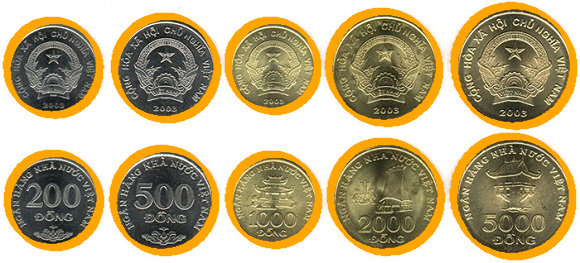

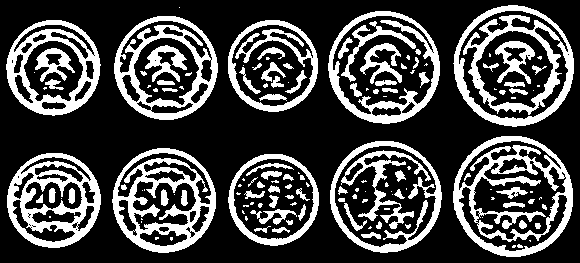

## Task 4: Phát hiện ký tự trên biển số xe



1. Sử dụng adaptive threshold để xử lý nền không đều.

2. Tìm contours đại diện cho các ký tự.

3. Lọc vùng nghi ngờ là ký tự dựa trên hình dạng hình học.

4. Cắt và lưu từng ký tự để chuẩn bị cho bước OCR hoặc nhận dạng ký tự.





Original Image Shape: (245, 270, 3)


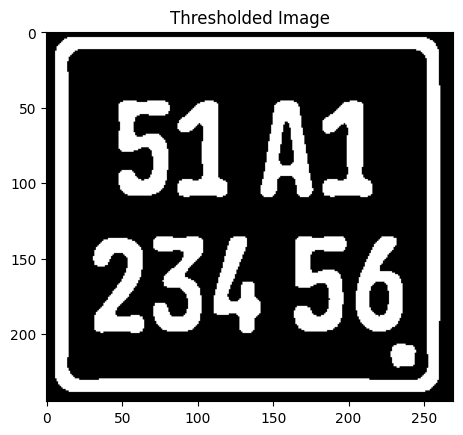

Number of Contours found = 0


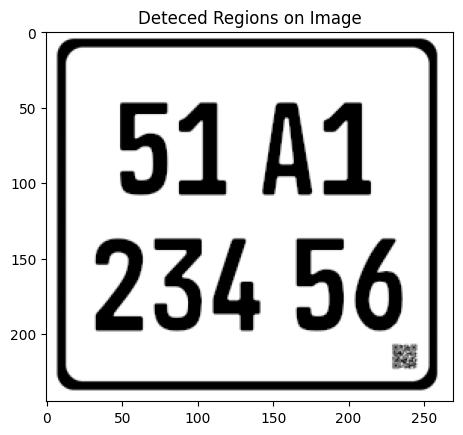

In [13]:
import cv2
import imutils
import matplotlib.pyplot as plt


img = cv2.imread('bien_so.jpg')
print("Original Image Shape:", img.shape)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY).astype(np.uint8)
blurred = cv2.GaussianBlur(gray, (11, 11), 0)
thres = cv2.adaptiveThreshold(
    src=blurred,
    maxValue=255,
    adaptiveMethod=cv2.ADAPTIVE_THRESH_MEAN_C,
    thresholdType=cv2.THRESH_BINARY_INV,
    blockSize=31,
    C=10
)

# Hiển thị ảnh
plt.imshow(thres, cmap="gray")
plt.title("Thresholded Image")
plt.show()

# Tìm các contours
contours = cv2.findContours(
    image=thres.copy(),
    mode=cv2.RETR_EXTERNAL,
    method=cv2.CHAIN_APPROX_NONE,
)
contours = contours[0]
# cv2.drawContours(img, contours, contourIdx=-1, color=(0, 255, 0))

number = 0
for c in contours:
    (x, y, w, h) = cv2.boundingRect(c)
    # Điều kiện lọc kích thước của vùng bounding box
    if (40 < w < 150) and (100 < h < 200) and (h / w > 1.5):
        number += 1
        # Crop phần ảnh theo vùng bounding box và lưu lại
        # crop = img[y: y+h, x: x+w]
        cv2.rectangle(img, (x, y), (x+w, y+h), (0, 255, 0), 2)
print("Number of Contours found = " + str(number))

# Hiển thị ảnh gốc với các bounding boxes
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Deteced Regions on Image")
plt.show()

```
Original Image Shape: (160, 722, 3)
```
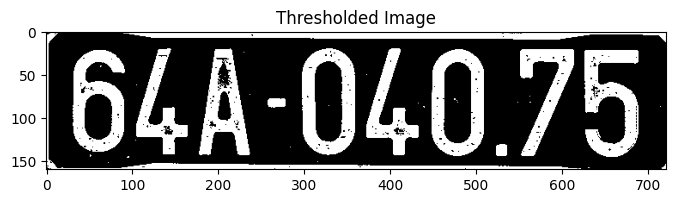

```
Number of Contours found = 8
```
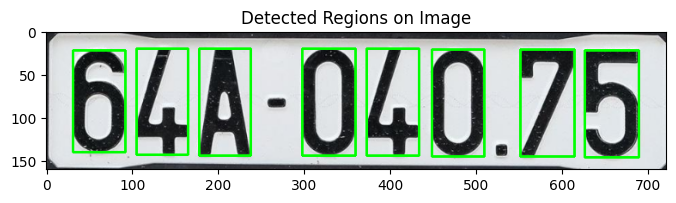

## Câu hỏi
1. Tại sao dùng adaptive threshold thay vì fixed threshold như cv2.threshold()?
- Fixed threshold đặt ngưỡng cố định cho toàn bộ ảnh, điều này không phù hợp với các ảnh có độ sáng không đều, các vùng sáng tối khác nhau.
- Adaptive Threshold tính ngưỡng cho từng vùng nhỏ trong ảnh, từ đó cải thiện việc ảnh bị ảnh hưởng bởi các yếu tố ánh sáng. Do đó cho kết quả tốt hơn ở ảnh thực tế.

2. Tỷ lệ h/w > 1.5 mang ý nghĩa gì? Tại sao quan trọng khi lọc ký tự?
- Tỷ lệ h/w đại diện cho chiều cao / chiều rộng. Tỷ lệ này > 1.5 giúp loại bỏ các contour nhiễu. Đây là một ngưỡng giúp xác định dúng các ký tự số.
- Rất quan trọng vì khi tìm contour có rất nhiều ký hiệu nhỏ không mong muốn như: dấu chấm, dấu gạch ngang, vết xước, ...

3. nếu biển số bị nghiêng hoặc có font chữ khác thường thì xử lý như thế nào?
- Nếu biển số nghiêng, có thể sử dụng các phép transform để làm phẳng biển số về mặt đứng.
- Font chữ khác thường, sử dụng mô hình phù hợp hơn hoặc có thể huấn luyện thêm cho mô hình bằng việc tăng cường dữ liệu font lạ.

In [14]:
!pip install opencv-python-headless
!pip install pytesseract
!apt-get install tesseract-ocr -y
!apt-get install libtesseract-dev -y


Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (4.1.1-2.1build1).
0 upgraded, 0 newly installed, 0 to remove and 35 not upgraded.
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libarchive-dev libleptonica-dev
The following NEW packages will be installed:
  libarchive-dev libleptonica-dev libtesseract-dev
0 upgraded, 3 newly installed, 0 to remove and 35 not upgraded.
Need to get 3,743 kB of archives.
After this operation, 16.0 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu jammy-updates/main amd64 libarchive-dev amd64 3.6.0-1ubuntu1.5 [581 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy/universe amd64 libleptonica-dev amd64 1.82.0-3build1 [1,562 kB]
Get:3 http://archive.ubuntu.com/ubuntu jammy/universe amd64 libtesseract-dev amd64 4.1.1-2.1build1 [1,600 kB

Task 5: Tự động nhận dạng biển số xe bằng Tesseract OCR

In [16]:
import cv2
import numpy as np
import pytesseract
from google.colab.patches import cv2_imshow

def preprocess_image(image):
    gray = None
    blur = None
    thresh = None
    return thresh

def find_contours(thresh):
    contours, _ = None
    return None

def get_license_plate(image, contours):
    for contour in contours:
        x, y, w, h = None
        aspect_ratio = None
        if 2.5 < aspect_ratio < 5.5:
            plate = None
            return None
    return None, None

def recognize_text(plate):
    config = ('-l eng --oem 1 --psm 7')
    text = None
    return text.strip()

def segment_characters(plate):
    # xử lý ảnh
    gray = None
    thresh = None

    # Tìm contours của các ký tự
    contours, _ = None

    char_boxes = []
    for contour in contours:
        x, y, w, h = None
        if h > 0.5 * plate.shape[0]:  # Lọc các contour quá nhỏ
            char_boxes.append((x, y, w, h))

    # Sắp xếp các ký tự từ trái sang phải
    char_boxes = None

    return char_boxes

# Đọc hình ảnh
image = cv2.imread('/content/bien_so2.jpg')
original_image = image.copy()

# Tiền xử lý ảnh
preprocessed = None

# Tìm contour
contours = None

# Tìm và cắt biển số
bbox = None
plate = None


if plate is not None:
    # Nhận dạng văn bản
    text = recognize_text(plate)
    print(f"Biển số xe: {text}")

    # Vẽ hình chữ nhật xung quanh biển số
    x, y, w, h = None

    print("Hình ảnh gốc với vùng biển số được đánh dấu:")
    cv2_imshow(original_image)

    print("\nVùng biển số đã được crop:")
    cv2_imshow(plate)

    # Phân đoạn và hiển thị từng ký tự
    char_boxes = segment_characters(plate)
    for i, (cx, cy, cw, ch) in enumerate(char_boxes):
        char_image = plate[cy:cy+ch, cx:cx+cw]
        print(f"\nKý tự {i+1}:")
        cv2_imshow(char_image)
else:
    print("Không tìm thấy biển số xe trong ảnh.")

Không tìm thấy biển số xe trong ảnh.


```
Biển số xe: 30A- 128.93;
Hình ảnh gốc với vùng biển số được đánh dấu:
```
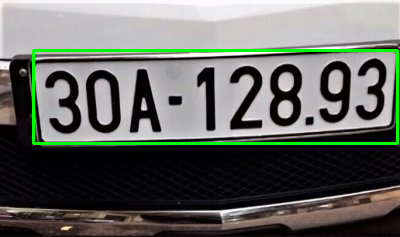

```
Vùng biển số đã được crop:
```
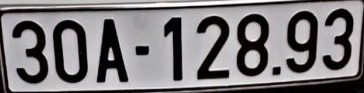

```
Ký tự 1:
```
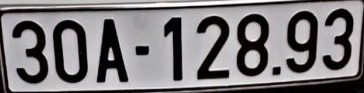
```
Ký tự 2:
```
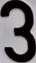
```
Ký tự 3:
```
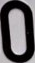

```
Ký tự 4:
```
image.png
```
Ký tự 5:
```
image.png
```
Ký tự 6:
```
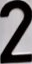
```
Ký tự 7:
```
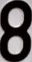
```
Ký tự 8:
```
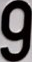
```
Ký tự 9:
```
image.png

## Câu hỏi:
1. Tại sao lại dùng tỷ lệ khung ảnh để xác định vùng biển số (aspect_ratio)?
- Aspect ratio là tỷ lệ giữa chiều rộng / chiều cao của bounding box. Vì biển số xe có hình chữ nhật đặc trưng nên tỷ lệ này thường rơi vào khoảng 3-8. Do đó nhờ vào aspect_ratio, chúng ta có thể loại bỏ những vùng contour nhiễu không phải biển số, cũng như xác định chính xác vùng biển số trong ảnh chứa nhiều contours.

2. Nếu biển số bị nghiêng hoặc bị che khuất? Cách khắc phục?
- Biển số bị nghiêng, chúng ta có thể sử dụng các phép biến đổi transform, để làm phẳng hình ảnh.
- Ảnh bị che khuất, cách đầu tiên là chụp lại ảnh khác. Nếu không, giải pháp chính là cải thiện mô hình nhận diện, có thể sử dụng các mô hình OCR có khả năng xử lý các kí tự không đầy đủ. Nếu bị che khuất hẳn chữ, không thể xử lý được, cần thông báo là biển số bị che (có thể dựa vào việc không đủ ký tự trên biển số, ...).

3. Bạn có thể cải thiện hệ thống này bằng cách dùng Deep Learning không? Gợi ý mô hình?
- Có thể sử dụng Deeplearning giúp mô hình tự học được các đặc trưng phức tạp từ dữ liệu, linh hoạt với nhiều kiểu biển số, điều kiện ánh sáng,...
- Có thể cải tiến với một số mô hình sau:
    - Phát hiện biển số: sử dụng YOLO, Faster R-CNN, ... Cũng có thể finetune các mô hình trên tập dữ liệu cụ thể để tăng độ chính xác.
    - Nhận dạng ký tự: CRNN, TrOCR, PaddleOCR,...

# Task 5: Trích xuất từng ký tự từ ảnh biển số xe:


Original Image Shape: (455, 680, 3)


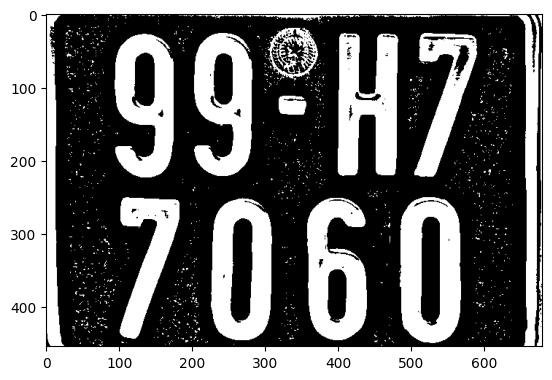

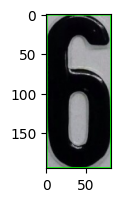

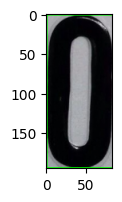

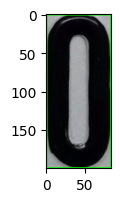

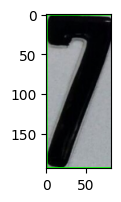

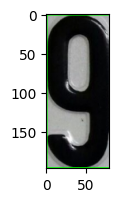

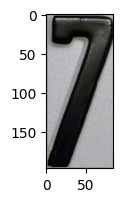

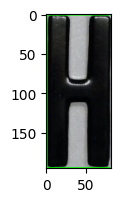

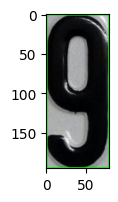

Number of Contours found = 8


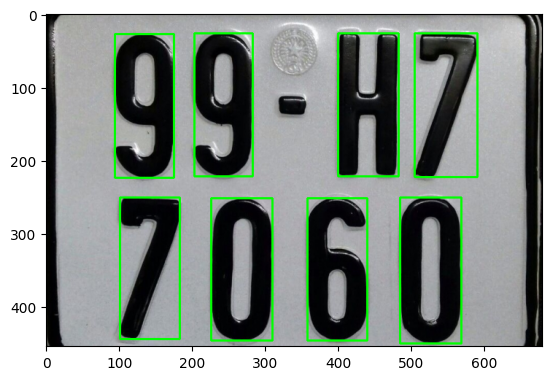

In [18]:
import cv2
import imutils
import matplotlib.pyplot as plt

img = cv2.imread('/content/bien_so3.jpg')
print("Original Image Shape:", img.shape)

# grayscale và áp dụng adaptive threshold
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
thres = cv2.adaptiveThreshold(
    src=gray,
    maxValue=255,
    adaptiveMethod=cv2.ADAPTIVE_THRESH_MEAN_C,
    thresholdType=cv2.THRESH_BINARY_INV,
    blockSize=31,
    C=5
)

# Hiển thị ảnh
plt.imshow(thres, cmap="gray")
plt.show()

# Tìm các contours
contours, _ = cv2.findContours(
    image=thres,
    mode=cv2.RETR_EXTERNAL,
    method=cv2.CHAIN_APPROX_NONE,
)

number = 0
for c in contours:
    (x, y, w, h) = cv2.boundingRect(c)

    if (40 < w < 150) and (120 < h < 300) and (h / w > 1.2):
        cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)
        number += 1
        crop = img[y: y+h, x: x+w]
        # cv2.imwrite(f"number{number}.png", crop)

        # Cropt ảnh
        plt.figure(figsize=(3,2))
        plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        plt.show()

print("Number of Contours found = " + str(number))

# Hiển thị ảnh gốc với các bounding boxes
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()


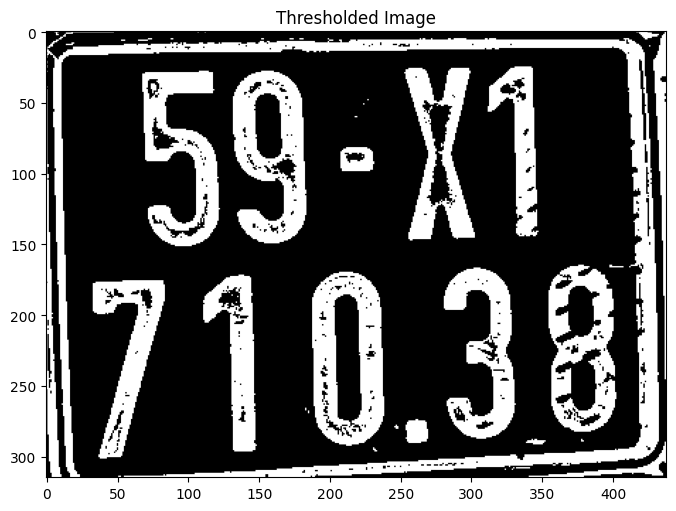

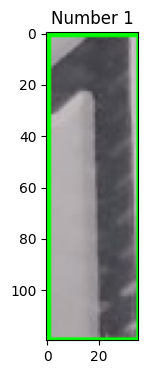

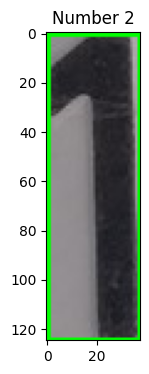

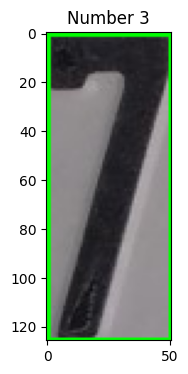

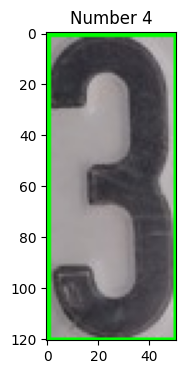

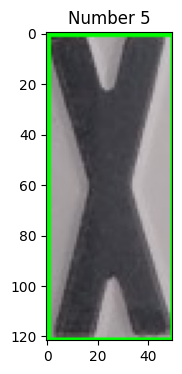

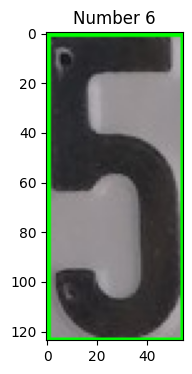

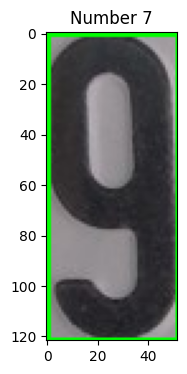


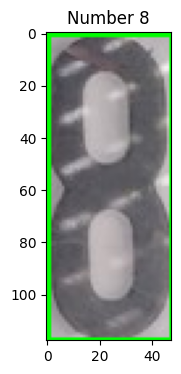

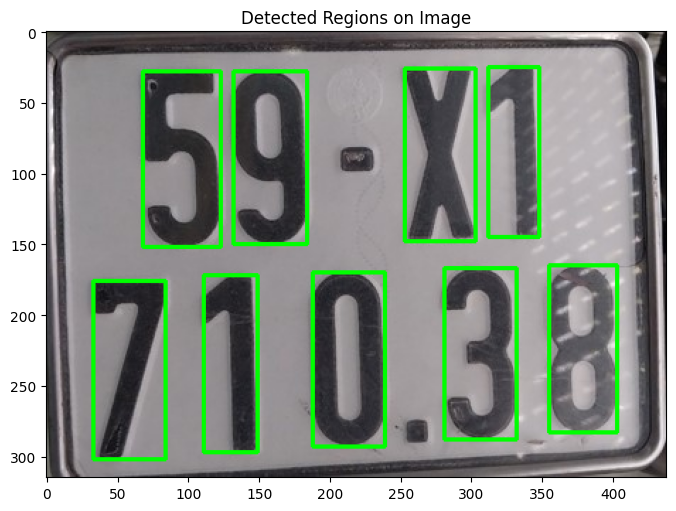

## Câu hỏi
1. Ý nghĩa của các tham số alpha, beta, và gamma trong Active Contour là gì?
- : Ý nghĩa của alpha, beta, gamma
Alpha: điều khiển độ co giãn của đường cong (alpha nhỏ → mềm, dễ biến dạng).

Beta: điều khiển độ mượt, giảm gấp khúc (beta lớn → đường cong mượt hơn).

Gamma: tốc độ cập nhật vị trí (gamma vừa phải giúp hội tụ ổn định).

2. Làm thế nào để lựa chọn vị trí và kích thước của đường cong ban đầu ảnh hưởng đến kết quả?
- Ảnh hưởng của vị trí và kích thước đường cong ban đầu
Nếu gần đúng đối tượng → hội tụ nhanh và chính xác.

Nếu quá xa hoặc sai kích thước → dễ hội tụ sai hoặc không hội tụ.